In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn

In [2]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully.")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully.


In [3]:
data = {
    "symptoms": [
        "What are common symptoms of heart disease?",
        "Why do I feel breathless when walking?",
        "What are the warning signs of heart failure?",
        "Can heart problems cause dizziness?",
        "What does an irregular heartbeat feel like?",
        "Why do I feel tired after little activity?",
        "What are symptoms of poor blood circulation?",
        "How can I recognize high blood pressure symptoms?"
    ],

    "prevention": [
        "How can I prevent heart disease?",
        "What lifestyle changes improve heart health?",
        "How can I reduce my risk of a heart attack?",
        "Does quitting smoking help the heart?",
        "How does stress affect heart health?",
        "How much sleep is good for the heart?",
        "Can regular health checkups prevent heart disease?",
        "How can I maintain healthy blood pressure?"
    ],

    "nutrition": [
        "What foods are good for heart health?",
        "Which foods should I avoid for a healthy heart?",
        "Is a low salt diet good for the heart?",
        "What is a heart healthy diet?",
        "Are fruits and vegetables good for the heart?",
        "Does eating too much saturated fat affect the heart?",
        "What are healthy alternatives to fried foods?",
        "How does a balanced diet help prevent heart disease?"
    ],

    "exercise": [
        "What exercises are good for heart health?",
        "How much physical activity should adults do?",
        "Is walking good for the heart?",
        "Can regular exercise lower blood pressure?",
        "What are the benefits of aerobic exercise?",
        "How can beginners start exercising safely?",
        "Does cycling improve cardiovascular fitness?",
        "Can exercise help reduce heart disease risk?"
    ],

    "medication": [
        "Why are blood pressure medicines prescribed?",
        "What are statins used for?",
        "What should I do if I forget my heart medicine?",
        "Can I stop taking prescribed heart medication?",
        "Why do doctors prescribe blood thinners?",
        "What are common side effects of heart medicines?",
        "Can medicines help control high blood pressure?",
        "Should I take my medication at the same time daily?"
    ]
}

df = pd.DataFrame([
    {"query": query, "intent": intent}
    for intent, queries in data.items()
    for query in queries
])

print("Total queries:", len(df))
print("\nQueries per intent:")
print(df["intent"].value_counts())

df.head()

Total queries: 40

Queries per intent:
intent
symptoms      8
prevention    8
nutrition     8
exercise      8
medication    8
Name: count, dtype: int64


,query,intent
0,What are common symptoms of heart disease?,symptoms
1,Why do I feel breathless when walking?,symptoms
2,What are the warning signs of heart failure?,symptoms
3,Can heart problems cause dizziness?,symptoms
4,What does an irregular heartbeat feel like?,symptoms


In [4]:
taxonomy = {
    "Heart Conditions": [
        "Symptoms and warning signs",
        "Risk factors and complications"
    ],

    "Healthy Lifestyle": [
        "Nutrition and diet",
        "Physical activity and exercise"
    ],

    "Medical Care": [
        "Medication information",
        "Health monitoring and checkups"
    ],

    "Safety and Support": [
        "Emergency response",
        "General health information"
    ]
}

for category, subcategories in taxonomy.items():
    print(category)

    for subcategory in subcategories:
        print("  └──", subcategory)

Heart Conditions
  └── Symptoms and warning signs
  └── Risk factors and complications
Healthy Lifestyle
  └── Nutrition and diet
  └── Physical activity and exercise
Medical Care
  └── Medication information
  └── Health monitoring and checkups
Safety and Support
  └── Emergency response
  └── General health information


In [5]:
concepts = {
    "Heart": "An organ that pumps blood throughout the body.",
    "Blood Pressure": "The force of blood against artery walls.",
    "Cholesterol": "A fatty substance found in the blood.",
    "Exercise": "Physical activity that improves fitness.",
    "Diet": "The foods and drinks consumed regularly.",
    "Smoking": "The use of tobacco products.",
    "Heart Disease": "A group of conditions affecting the heart.",
    "Medication": "A substance used to prevent or treat disease.",
    "Stress": "A physical or emotional response to pressure.",
    "Emergency Services": "Services that provide urgent medical assistance."
}

relationships = [
    ("Heart Disease", "affects", "Heart"),
    ("High Blood Pressure", "increases risk of", "Heart Disease"),
    ("High Cholesterol", "increases risk of", "Heart Disease"),
    ("Exercise", "helps reduce", "Blood Pressure"),
    ("Exercise", "improves", "Heart Health"),
    ("Healthy Diet", "helps control", "Cholesterol"),
    ("Smoking", "increases risk of", "Heart Disease"),
    ("Stress", "may affect", "Blood Pressure"),
    ("Medication", "may help control", "Blood Pressure"),
    ("Heart Attack", "requires urgent help from", "Emergency Services"),
    ("Heart Disease", "may require", "Medication"),
    ("Healthy Diet", "supports", "Heart Health")
]

print("Domain Concepts:")
for concept, definition in concepts.items():
    print(f"{concept}: {definition}")

print("\nKnowledge Graph Relationships:")
for subject, relation, obj in relationships:
    print(f"{subject} --{relation}--> {obj}")

Domain Concepts:
Heart: An organ that pumps blood throughout the body.
Blood Pressure: The force of blood against artery walls.
Cholesterol: A fatty substance found in the blood.
Exercise: Physical activity that improves fitness.
Diet: The foods and drinks consumed regularly.
Smoking: The use of tobacco products.
Heart Disease: A group of conditions affecting the heart.
Medication: A substance used to prevent or treat disease.
Stress: A physical or emotional response to pressure.
Emergency Services: Services that provide urgent medical assistance.

Knowledge Graph Relationships:
Heart Disease --affects--> Heart
High Blood Pressure --increases risk of--> Heart Disease
High Cholesterol --increases risk of--> Heart Disease
Exercise --helps reduce--> Blood Pressure
Exercise --improves--> Heart Health
Healthy Diet --helps control--> Cholesterol
Smoking --increases risk of--> Heart Disease
Stress --may affect--> Blood Pressure
Medication --may help control--> Blood Pressure
Heart Attack --re

In [6]:
stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"no", "not", "never"}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal and lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess_text)

print(df[["query", "processed_query", "intent"]].head(10))

                                               query  \
0         What are common symptoms of heart disease?   
1             Why do I feel breathless when walking?   
2       What are the warning signs of heart failure?   
3                Can heart problems cause dizziness?   
4        What does an irregular heartbeat feel like?   
5         Why do I feel tired after little activity?   
6       What are symptoms of poor blood circulation?   
7  How can I recognize high blood pressure symptoms?   
8                   How can I prevent heart disease?   
9       What lifestyle changes improve heart health?   

                         processed_query      intent  
0           common symptom heart disease    symptoms  
1                feel breathless walking    symptoms  
2             warning sign heart failure    symptoms  
3          heart problem cause dizziness    symptoms  
4          irregular heartbeat feel like    symptoms  
5             feel tired little activity    symptoms 

In [7]:
X = df["processed_query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model training completed.
Training samples: 30
Testing samples: 10


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("Accuracy:", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.4
Precision: 0.517
Recall: 0.4
F1-score: 0.413

Classification Report:
              precision    recall  f1-score   support

    exercise       0.00      0.00      0.00         2
  medication       1.00      0.50      0.67         2
   nutrition       1.00      0.50      0.67         2
  prevention       0.25      0.50      0.33         2
    symptoms       0.33      0.50      0.40         2

    accuracy                           0.40        10
   macro avg       0.52      0.40      0.41        10
weighted avg       0.52      0.40      0.41        10



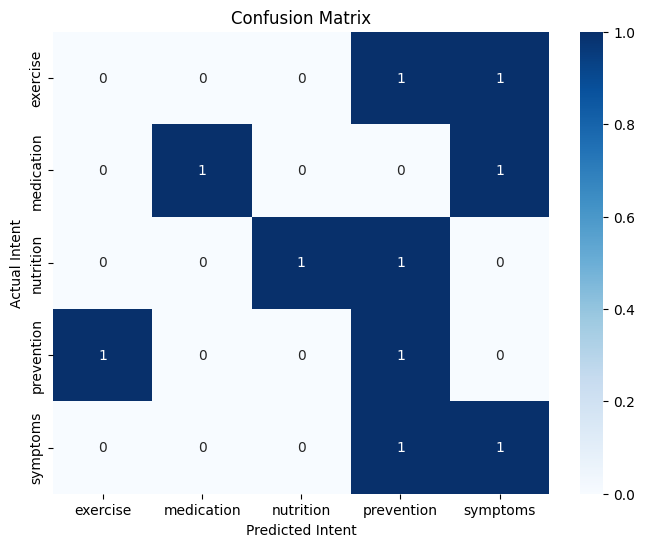

In [9]:
labels = model.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Confusion Matrix")
plt.show()

In [10]:
knowledge_base = {
    "symptoms": """
    Heart disease may cause chest discomfort, shortness of breath,
    unusual fatigue, dizziness, or an irregular heartbeat.
    Symptoms vary between individuals. Some people may have no
    noticeable symptoms. Seek medical advice for concerning symptoms.
    """,

    "prevention": """
    Heart health can be supported by avoiding smoking, eating a
    balanced diet, staying physically active, managing stress,
    getting adequate sleep, and attending regular health checkups.
    """,

    "nutrition": """
    A heart healthy diet includes vegetables, fruits, whole grains,
    legumes, nuts, and appropriate sources of protein. Limiting
    excess salt, saturated fat, and highly processed foods may
    support cardiovascular health.
    """,

    "exercise": """
    Regular physical activity supports cardiovascular fitness.
    Adults are generally advised to aim for at least 150 minutes
    of moderate-intensity aerobic activity per week, if appropriate
    for their health. Begin gradually and seek medical advice when needed.
    """,

    "medication": """
    Heart medicines may be prescribed to control blood pressure,
    cholesterol, blood clotting, or other cardiovascular conditions.
    Take medicines according to the prescribing clinician's instructions.
    Do not stop or change prescribed medication without medical advice.
    """
}

In [11]:
import numpy as np

EMERGENCY_KEYWORDS = [
    "heart attack",
    "chest pain",
    "chest pressure",
    "cannot breathe",
    "can't breathe",
    "severe shortness of breath",
    "stroke",
    "face drooping",
    "sudden weakness",
    "fainting"
]

def is_emergency(query):
    query = query.lower()

    return any(
        keyword in query
        for keyword in EMERGENCY_KEYWORDS
    )

def get_response(query):
    # Rule 1: Emergency escalation
    if is_emergency(query):
        return (
            "EMERGENCY ALERT: This may be a medical emergency. "
            "Call your local emergency number immediately. "
            "In India, call 112 or 108 for emergency medical assistance. "
            "Do not drive yourself. Follow the emergency operator's instructions."
        )

    # Rule 2: Predict intent and confidence
    processed_query = preprocess_text(query)

    probabilities = model.predict_proba([processed_query])[0]

    predicted_index = np.argmax(probabilities)
    predicted_intent = model.classes_[predicted_index]
    confidence = probabilities[predicted_index]

    print("Predicted Intent:", predicted_intent)
    print("Confidence:", round(float(confidence), 3))

    # Rule 3: Low-confidence handling
    if confidence < 0.25:
        return (
            "I'm not confident enough to understand your question. "
            "Please rephrase it or ask about heart symptoms, prevention, "
            "nutrition, exercise, or medication information."
        )

    # Rule 4: Unsupported-query handling
    supported_terms = [
        "heart", "cardiac", "blood pressure", "cholesterol",
        "exercise", "diet", "medicine", "medication",
        "symptom", "health", "smoking", "nutrition"
    ]

    if not any(term in query.lower() for term in supported_terms):
        return (
            "Sorry, this question is outside my heart-health knowledge base. "
            "I can answer general questions about heart symptoms, prevention, "
            "nutrition, exercise, and medication information."
        )

    # Rule 5: Retrieve information from the knowledge base
    response = knowledge_base.get(predicted_intent)

    if response:
        return response

    return (
        "I could not find relevant information. "
        "Please consult a qualified healthcare professional."
    )

In [12]:
test_queries = [
    "What are common symptoms of heart disease?",
    "How can I keep my heart healthy?",
    "Which foods are good for my heart?",
    "Is walking beneficial for cardiovascular health?",
    "What are blood pressure medicines used for?",

    # Differently worded query
    "How do I take care of my cardiovascular system?",

    # Unsupported query
    "How do I repair a broken laptop?",

    # Low-confidence query
    "Tell me something",

    # Emergency query
    "I have severe chest pain and cannot breathe."
]

for query in test_queries:
    print("\nUser:", query)
    print("Assistant:", get_response(query))
    print("-" * 60)


User: What are common symptoms of heart disease?
Predicted Intent: symptoms
Confidence: 0.357
Assistant: 
    Heart disease may cause chest discomfort, shortness of breath,
    unusual fatigue, dizziness, or an irregular heartbeat.
    Symptoms vary between individuals. Some people may have no
    noticeable symptoms. Seek medical advice for concerning symptoms.
    
------------------------------------------------------------

User: How can I keep my heart healthy?
Predicted Intent: nutrition
Confidence: 0.34
Assistant: 
    A heart healthy diet includes vegetables, fruits, whole grains,
    legumes, nuts, and appropriate sources of protein. Limiting
    excess salt, saturated fat, and highly processed foods may
    support cardiovascular health.
    
------------------------------------------------------------

User: Which foods are good for my heart?
Predicted Intent: nutrition
Confidence: 0.371
Assistant: 
    A heart healthy diet includes vegetables, fruits, whole grains,
    leg

In [15]:
print("HEART HEALTH INFORMATION ASSISTANT")
print("Ask a question about heart health.")
print("Type 'exit' to stop.")

while True:
    user_query = input("\nYou: ")

    if user_query.lower().strip() == "exit":
        print("Assistant: Stay healthy!")
        break

    response = get_response(user_query)

    print("\nAssistant:", response)

HEART HEALTH INFORMATION ASSISTANT
Ask a question about heart health.
Type 'exit' to stop.

You: What are common symptoms of heart disease?
Predicted Intent: symptoms
Confidence: 0.357

Assistant: 
    Heart disease may cause chest discomfort, shortness of breath,
    unusual fatigue, dizziness, or an irregular heartbeat.
    Symptoms vary between individuals. Some people may have no
    noticeable symptoms. Seek medical advice for concerning symptoms.
    

You: exit
Assistant: Stay healthy!
